<a href="https://colab.research.google.com/github/prantiqueroy/dhaka-air-enforcement/blob/main/notebooks/06_main_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

RAW = "https://raw.githubusercontent.com/prantiqueroy/dhaka-air-enforcement/main/data/"
d  = pd.read_csv(RAW + "dhaka_daily_adjusted.csv", index_col=0, parse_dates=True)
tl = pd.read_csv(RAW + "enforcement_timeline.csv")
ne = pd.read_csv(RAW + "natural_experiments.csv")
tl["date"] = pd.to_datetime(tl["date"], dayfirst=True, format="mixed")
ne["start_date"] = pd.to_datetime(ne["start_date"], dayfirst=True, format="mixed")

moon_fix = {"Eid ul-Fitr 2016": "2016-07-07", "Eid ul-Fitr 2018": "2018-06-16", "Eid ul-Fitr 2024": "2024-04-11"}
for event, day in moon_fix.items():
    ne.loc[ne["event"] == event, "start_date"] = pd.Timestamp(day)
print("Days:", len(d), "| Timeline events:", len(tl))

Days: 2478 | Timeline events: 28


In [2]:
eid_days = ne.loc[ne["event"].str.startswith("Eid"), "start_date"]
s = d["adjusted_pct"].copy()
for e in eid_days:
    s.loc[e - pd.Timedelta(days=1): e + pd.Timedelta(days=3)] = np.nan
s.loc["2020-03-26":"2020-05-30"] = np.nan
s = s.dropna()
print("Days used after dropping Eid and COVID days:", len(s))

Days used after dropping Eid and COVID days: 2367


In [4]:
FROZEN = ["E01","E02","E03","E04","E08","E10","E11","E12","E14","E15","E24","E25"]   # from the OSF plan
ev = tl[tl["event_id"].isin(FROZEN)].sort_values("date")[["event_id", "date", "tool"]]
ev["cluster"] = (ev["date"].diff().dt.days.fillna(999) >= 30).cumsum()
clusters = ev.groupby("cluster").agg(date=("date", "first"), events=("event_id", "+".join), tool=("tool", "first"))
print(clusters.to_string())

              date   events                   tool
cluster                                           
1       2019-01-28      E01            Court order
2       2019-03-13      E02  Court order (summons)
3       2019-05-05      E03  Court order (summons)
4       2019-11-26      E04            Court order
5       2020-01-13      E08            Court order
6       2020-11-24      E10            Court order
7       2021-01-11  E11+E12             Demolition
8       2022-03-01      E14            Court order
9       2022-04-20      E15  Court order (summons)
10      2025-01-02  E24+E25           Mobile court


          events       date  effect
cluster                            
1            E01 2019-01-28    27.1
2            E02 2019-03-13     5.3
3            E03 2019-05-05   -11.2
4            E04 2019-11-26   -12.3
5            E08 2020-01-13    -7.5
6            E10 2020-11-24     8.0
7        E11+E12 2021-01-11     9.0
8            E14 2022-03-01    31.2
9            E15 2022-04-20    33.2
10       E24+E25 2025-01-02   -10.2

Average effect: 7.3 % across 10 clusters
(negative = air cleaner after the action; positive = dirtier)


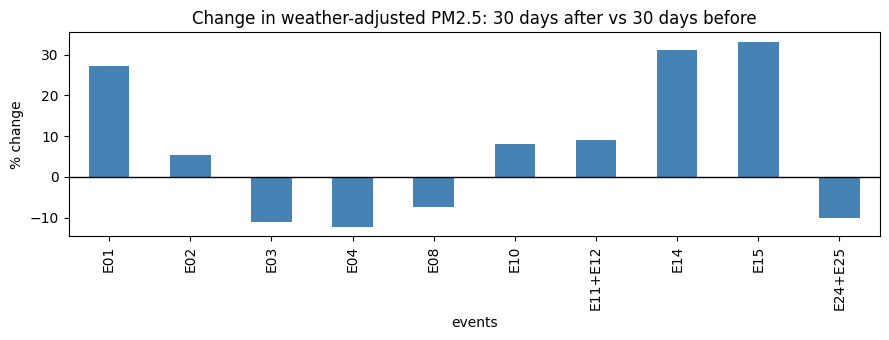

In [5]:
# effect = average weather-adjusted PM2.5 in the 30 days after, minus the 30 days before
# A window needs at least half its days with data (15 of 30, as pre-registered)
def effect(day, before=(-30, -1), after=(1, 30)):
    b = s.loc[day + pd.Timedelta(days=before[0]): day + pd.Timedelta(days=before[1])]
    a = s.loc[day + pd.Timedelta(days=after[0]):  day + pd.Timedelta(days=after[1])]
    need_b = min(15, (before[1] - before[0] + 1) // 2)
    need_a = min(15, (after[1] - after[0] + 1) // 2)
    if len(b) < need_b or len(a) < need_a:
        return np.nan
    return a.mean() - b.mean()

clusters["effect"] = [round(effect(x), 1) for x in clusters["date"]]
print(clusters[["events", "date", "effect"]].to_string())
obs = clusters["effect"].mean()
n = clusters["effect"].notna().sum()
print("\nAverage effect:", round(obs, 1), "% across", n, "clusters")
print("(negative = air cleaner after the action; positive = dirtier)")

clusters.plot(x="events", y="effect", kind="bar", color="steelblue", legend=False, figsize=(9, 3.5))
plt.axhline(0, color="black", lw=1)
plt.title("Change in weather-adjusted PM2.5: 30 days after vs 30 days before")
plt.ylabel("% change"); plt.tight_layout(); plt.show()

Random sets of 10 dates: average -1.6 %, spread (SD) 5.0 %
H1 p-value (share of random sets as LOW or lower): 0.97
Share of random sets as HIGH or higher: 0.03


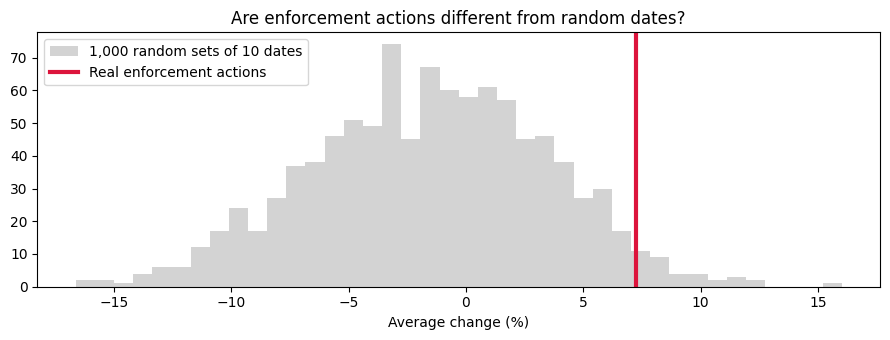

In [6]:
rng = np.random.default_rng(0)
avoid = pd.concat([tl["date"], eid_days, pd.Series(pd.date_range("2020-03-26", "2020-05-30"))])
cand = d.index[(d.index > "2016-05-01") & (d.index < "2025-02-01")]
dist = np.array([np.abs((avoid.values - np.datetime64(c)).astype("timedelta64[D]").astype(int)).min() for c in cand])
pool = cand[dist >= 40]

cache = {}
def placebo_effect(day):
    if day not in cache:
        cache[day] = effect(day)
    return cache[day]

fake = []
while len(fake) < 1000:
    days = rng.choice(pool, n * 2, replace=False)
    vals = [v for v in (placebo_effect(pd.Timestamp(x)) for x in days) if not np.isnan(v)][:n]
    if len(vals) == n:
        fake.append(np.mean(vals))
fake = np.array(fake)

print("Random sets of", n, "dates: average", round(fake.mean(), 1), "%, spread (SD)", round(fake.std(), 1), "%")
print("H1 p-value (share of random sets as LOW or lower):", round((fake <= obs).mean(), 3))
print("Share of random sets as HIGH or higher:", round((fake >= obs).mean(), 3))

plt.figure(figsize=(9, 3.5))
plt.hist(fake, bins=40, color="lightgrey", label=f"1,000 random sets of {n} dates")
plt.axvline(obs, color="crimson", lw=3, label="Real enforcement actions")
plt.title("Are enforcement actions different from random dates?")
plt.xlabel("Average change (%)"); plt.legend(); plt.tight_layout(); plt.show()

In [7]:
clusters["first_10_days"] = [round(effect(x, after=(1, 10)), 1) for x in clusters["date"]]
clusters["days_21_30"]   = [round(effect(x, after=(21, 30)), 1) for x in clusters["date"]]
print(clusters[["events", "first_10_days", "days_21_30"]].to_string())
print("Average, first 10 days:", round(clusters["first_10_days"].mean(), 1), "%")
print("Average, days 21-30:  ", round(clusters["days_21_30"].mean(), 1), "%")

          events  first_10_days  days_21_30
cluster                                    
1            E01           40.8         7.8
2            E02          -21.1        23.3
3            E03            NaN       -29.6
4            E04          -13.8        -2.2
5            E08          -10.5       -10.9
6            E10           -1.6        11.7
7        E11+E12           29.6       -12.8
8            E14           31.2         NaN
9            E15           36.3        29.2
10       E24+E25          -19.1        -2.8
Average, first 10 days: 8.0 %
Average, days 21-30:   1.5 %


In [8]:
def run(dates, before=(-30, -1), after=(1, 30)):
    v = [effect(x, before, after) for x in dates]
    v = [x for x in v if not np.isnan(x)]
    return round(np.mean(v), 1), len(v)

base   = list(clusters["date"])
no_sum = list(clusters.loc[~clusters["tool"].str.contains("summons"), "date"])
alt    = [pd.Timestamp("2021-01-04") if x == pd.Timestamp("2021-01-11") else x for x in base]

print("Main test (30 days):        ", run(base))
print("Without summonses:          ", run(no_sum))
print("E11 dated 4 Jan 2021:       ", run(alt))
print("15-day windows:             ", run(base, (-15, -1), (1, 15)))
print("60-day windows:             ", run(base, (-60, -1), (1, 60)))

Main test (30 days):         (np.float64(7.3), 10)
Without summonses:           (np.float64(6.5), 7)
E11 dated 4 Jan 2021:        (np.float64(8.2), 10)
15-day windows:              (np.float64(10.5), 9)
60-day windows:              (np.float64(9.3), 10)


In [9]:
clusters.to_csv("main_test_results.csv")
print("Saved")

Saved
